In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        os.path.join(dirname, filename)

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

## Unet

Training with 2352 images, validating with 588 images.
Starting training on cuda...


Epoch 1/10 [Validate]: 100%|██████████| 74/74 [00:45<00:00,  1.63it/s, Loss=0.2735, Acc=87.95%]



Epoch [1/10] -> Train Loss: 0.3476, Train Acc: 86.80% | Val Loss: 0.3030, Val Acc: 87.95%
--------------------------------------------------------------------------------


Epoch 2/10 [Validate]: 100%|██████████| 74/74 [00:13<00:00,  5.67it/s, Loss=0.1157, Acc=89.44%]



Epoch [2/10] -> Train Loss: 0.2648, Train Acc: 89.56% | Val Loss: 0.2519, Val Acc: 89.44%
--------------------------------------------------------------------------------


Epoch 4/10 [Validate]: 100%|██████████| 74/74 [00:13<00:00,  5.67it/s, Loss=0.1027, Acc=90.54%]


... (9 outputs left out)

Epoch 9/10 [Validate]: 100%|██████████| 74/74 [00:13<00:00,  5.66it/s, Loss=0.0933, Acc=91.18%]



Epoch [9/10] -> Train Loss: 0.1690, Train Acc: 93.03% | Val Loss: 0.2049, Val Acc: 91.18%
--------------------------------------------------------------------------------


Epoch 10/10 [Validate]: 100%|██████████| 74/74 [00:13<00:00,  5.66it/s, Loss=0.0744, Acc=92.26%]


Epoch [10/10] -> Train Loss: 0.1585, Train Acc: 93.47% | Val Loss: 0.1796, Val Acc: 92.26%
--------------------------------------------------------------------------------
Visualizing model predictions...


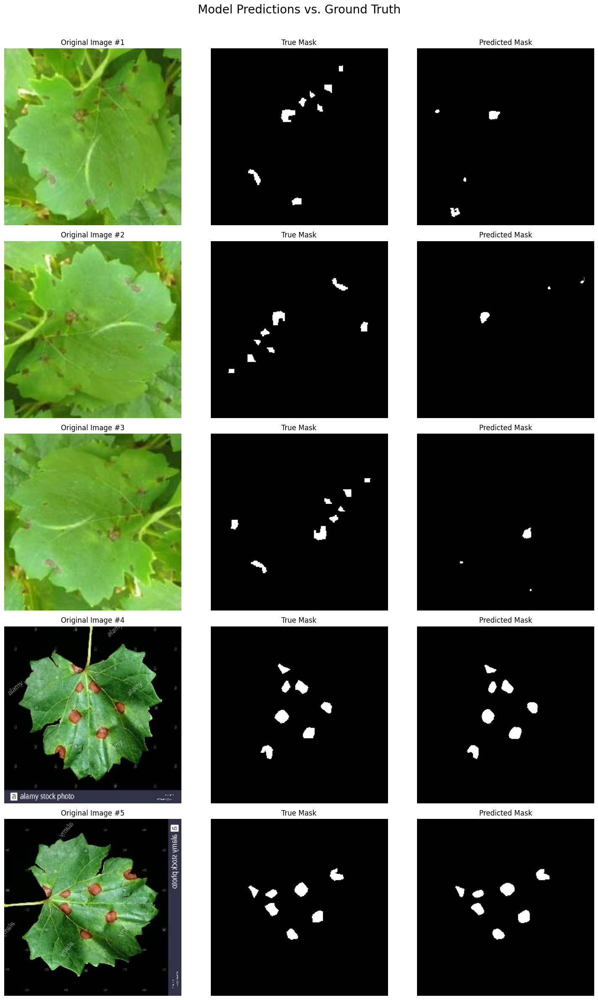

In [2]:
import os
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt
from tqdm import tqdm
import warnings

# Suppress minor warnings
warnings.filterwarnings("ignore")

# --- 1. Model Definition (U-Net) ---
class DoubleConv(nn.Module):
    """(Conv2D → BN → ReLU) * 2"""
    def __init__(self, in_channels, out_channels):
        super(DoubleConv, self).__init__()
        self.double_conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.double_conv(x)

class UNet(nn.Module):
    def __init__(self, n_classes=2):
        super(UNet, self).__init__()
        self.enc1 = DoubleConv(3, 64)
        self.enc2 = DoubleConv(64, 128)
        self.enc3 = DoubleConv(128, 256)
        self.enc4 = DoubleConv(256, 512)
        self.pool = nn.MaxPool2d(2)

        self.bottom = DoubleConv(512, 1024)

        self.upconv4 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
        self.dec4 = DoubleConv(1024, 512)
        self.upconv3 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.dec3 = DoubleConv(512, 256)
        self.upconv2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.dec2 = DoubleConv(256, 128)
        self.upconv1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec1 = DoubleConv(128, 64)
        self.final_conv = nn.Conv2d(64, n_classes, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b = self.bottom(self.pool(e4))
        d4 = self.upconv4(b)
        d4 = torch.cat([d4, e4], dim=1)
        d4 = self.dec4(d4)
        d3 = self.upconv3(d4)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)
        d2 = self.upconv2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)
        d1 = self.upconv1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)
        return self.final_conv(d1)

# --- 2. Custom Dataset Class ---
class LeafSegDataset(Dataset):
    def __init__(self, img_dir, mask_dir, img_files, mask_files, transform=None):
        self.img_dir = img_dir
        self.mask_dir = mask_dir
        self.transform = transform
        self.img_files = img_files
        self.mask_files = mask_files

    def __len__(self):
        return len(self.img_files)

    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.img_files[idx])
        mask_path = os.path.join(self.mask_dir, self.mask_files[idx])
        img = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path).convert("L") # Ensure mask is grayscale

        if self.transform:
            img = self.transform(img)
            # Use NEAREST interpolation for masks to preserve class labels 0 and 38
            mask = transforms.Resize((256, 256), interpolation=transforms.InterpolationMode.NEAREST)(mask)

        mask = np.array(mask, dtype=np.uint8)
        # **Crucial Step**: Remap pixel values {0 -> 0, 38 -> 1}
        mask = np.where(mask == 38, 1, 0)
        mask = torch.tensor(mask, dtype=torch.long)
        return img, mask

# --- 3. Training Loop Function ---
def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=10):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)
    print(f"Starting training on {device}...")
    
    for epoch in range(num_epochs):
        model.train()
        train_loss, train_correct, train_total = 0.0, 0, 0
        train_pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Train]")

        for images, masks in train_pbar:
            images, masks = images.to(device), masks.to(device)
            outputs = model(images)
            loss = criterion(outputs, masks)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            
            _, preds = torch.max(outputs, 1)
            train_total += masks.numel()
            train_correct += (preds == masks).sum().item()
            train_loss += loss.item() * images.size(0)
            train_pbar.set_postfix({'Loss': f"{loss.item():.4f}", 'Acc': f"{(100 * train_correct / train_total):.2f}%"})

        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        val_pbar = tqdm(val_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Validate]")

        with torch.no_grad():
            for images, masks in val_pbar:
                images, masks = images.to(device), masks.to(device)
                outputs = model(images)
                loss = criterion(outputs, masks)
                _, preds = torch.max(outputs, 1)
                val_total += masks.numel()
                val_correct += (preds == masks).sum().item()
                val_loss += loss.item() * images.size(0)
                val_pbar.set_postfix({'Loss': f"{loss.item():.4f}", 'Acc': f"{(100 * val_correct / val_total):.2f}%"})
        
        avg_train_loss = train_loss / len(train_loader.dataset)
        avg_val_loss = val_loss / len(val_loader.dataset)
        train_accuracy = 100 * train_correct / train_total
        val_accuracy = 100 * val_correct / val_total
        
        print(f"\nEpoch [{epoch+1}/{num_epochs}] -> Train Loss: {avg_train_loss:.4f}, Train Acc: {train_accuracy:.2f}% | Val Loss: {avg_val_loss:.4f}, Val Acc: {val_accuracy:.2f}%")
        print("-" * 80)

    return model

# --- 4. Visualization Function ---
def visualize_predictions(model, loader, device, num_images=5):
    print("Visualizing model predictions...")
    model.eval()
    images, masks = next(iter(loader))
    images = images.to(device)
    
    with torch.no_grad():
        outputs = model(images)
        _, preds = torch.max(outputs, 1)

    images = images.cpu()
    preds = preds.cpu()

    fig, axs = plt.subplots(num_images, 3, figsize=(15, num_images * 5))
    fig.suptitle("Model Predictions vs. Ground Truth", fontsize=20)

    for i in range(num_images):
        img = images[i].permute(1, 2, 0).numpy()
        
        axs[i, 0].imshow(img)
        axs[i, 0].set_title(f"Original Image #{i+1}")
        axs[i, 0].axis('off')

        axs[i, 1].imshow(masks[i], cmap='gray')
        axs[i, 1].set_title("True Mask")
        axs[i, 1].axis('off')

        axs[i, 2].imshow(preds[i], cmap='gray')
        axs[i, 2].set_title("Predicted Mask")
        axs[i, 2].axis('off')

    plt.tight_layout(rect=[0, 0.03, 1, 0.97])
    plt.show()

# --- 5. Main Execution ---
# Configuration
IMG_DIR = "/kaggle/input/leaf-disease-segmentation-dataset/aug_data/aug_data/images"
MASK_DIR = "/kaggle/input/leaf-disease-segmentation-dataset/aug_data/aug_data/masks"
BATCH_SIZE = 8
LEARNING_RATE = 1e-4
NUM_EPOCHS = 10 # Increase for better results

# Define transforms
img_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
])

# Create train/val split (80/20)
# NOTE: For robust results, use a more random split or predefined split files
all_img_files = sorted(os.listdir(IMG_DIR))
all_mask_files = sorted(os.listdir(MASK_DIR))
split_idx = int(len(all_img_files) * 0.8)

train_img_files = all_img_files[:split_idx]
train_mask_files = all_mask_files[:split_idx]
val_img_files = all_img_files[split_idx:]
val_mask_files = all_mask_files[split_idx:]

# Create Datasets
train_dataset = LeafSegDataset(IMG_DIR, MASK_DIR, train_img_files, train_mask_files, transform=img_transform)
val_dataset = LeafSegDataset(IMG_DIR, MASK_DIR, val_img_files, val_mask_files, transform=img_transform)

print(f"Training with {len(train_dataset)} images, validating with {len(val_dataset)} images.")

# Create DataLoaders
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

# Initialize Model, Loss, and Optimizer
model = UNet(n_classes=2)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

# Train the model
trained_model = train_model(
    model, train_loader, val_loader, criterion, optimizer, num_epochs=NUM_EPOCHS
)

# Visualize results on the validation set
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
visualize_predictions(trained_model, val_loader, device=device, num_images=min(5, len(val_dataset)))

## UNET V2

Training with 2352 images, validating with 588 images.
Starting U-Net training on cuda...


Epoch 1/10 [Train]: 100%|██████████| 147/147 [01:58<00:00,  1.24it/s, Loss=0.4513]



Epoch [1/10] -> Train Loss: 0.5071 | Val Loss: 0.4213 | Val IoU: 0.4918 | Val Dice: 0.6559
--------------------------------------------------------------------------------


Epoch 3/10 [Train]: 100%|██████████| 147/147 [01:58<00:00,  1.24it/s, Loss=0.2590]



Epoch [3/10] -> Train Loss: 0.3607 | Val Loss: 0.3279 | Val IoU: 0.5495 | Val Dice: 0.7056
--------------------------------------------------------------------------------


Epoch 4/10 [Train]: 100%|██████████| 147/147 [01:58<00:00,  1.24it/s, Loss=0.3135]


... (9 outputs left out)

Epoch 9/10 [Train]: 100%|██████████| 147/147 [01:58<00:00,  1.24it/s, Loss=0.2777]



Epoch [9/10] -> Train Loss: 0.2468 | Val Loss: 0.2513 | Val IoU: 0.6094 | Val Dice: 0.7549
--------------------------------------------------------------------------------


Epoch 10/10 [Train]: 100%|██████████| 147/147 [01:59<00:00,  1.23it/s, Loss=0.4360]



Epoch [10/10] -> Train Loss: 0.2407 | Val Loss: 0.2464 | Val IoU: 0.6152 | Val Dice: 0.7589
--------------------------------------------------------------------------------

U-Net training history saved to /kaggle/working/unet_history.pkl
U-Net model weights saved to /kaggle/working/unet_model.pth
Visualizing model predictions...


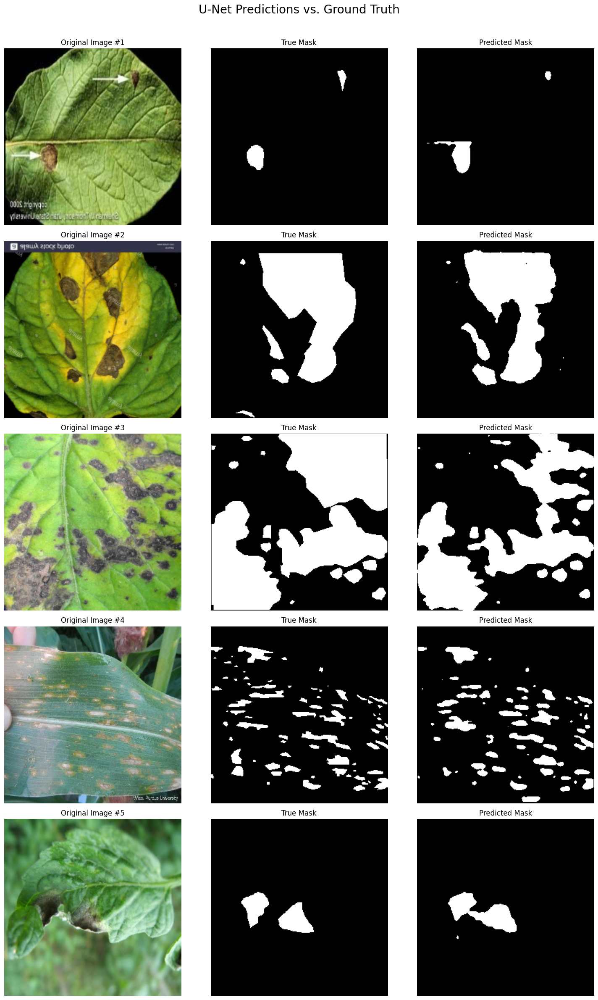

In [3]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt
from tqdm import tqdm
import pickle
import warnings

# Suppress minor warnings
warnings.filterwarnings("ignore")

# --- 1. Dice Loss Function ---
class DiceLoss(nn.Module):
    def __init__(self, smooth=1.0):
        super(DiceLoss, self).__init__()
        self.smooth = smooth

    def forward(self, outputs, masks):
        outputs = F.softmax(outputs, dim=1)[:, 1] # Probabilities of class 1
        masks = masks.float()
        intersection = (outputs * masks).sum()
        dice_coeff = (2. * intersection + self.smooth) / (outputs.sum() + masks.sum() + self.smooth)
        return 1 - dice_coeff

# --- 2. Model Definition (U-Net) ---
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(DoubleConv, self).__init__()
        self.double_conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True),
        )
    def forward(self, x): return self.double_conv(x)

class UNet(nn.Module):
    def __init__(self, n_classes=2):
        super(UNet, self).__init__()
        self.enc1 = DoubleConv(3, 64)
        self.enc2 = DoubleConv(64, 128)
        self.enc3 = DoubleConv(128, 256)
        self.enc4 = DoubleConv(256, 512)
        self.pool = nn.MaxPool2d(2)
        self.bottom = DoubleConv(512, 1024)
        self.upconv4 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
        self.dec4 = DoubleConv(1024, 512)
        self.upconv3 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.dec3 = DoubleConv(512, 256)
        self.upconv2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.dec2 = DoubleConv(256, 128)
        self.upconv1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec1 = DoubleConv(128, 64)
        self.final_conv = nn.Conv2d(64, n_classes, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x); e2 = self.enc2(self.pool(e1)); e3 = self.enc3(self.pool(e2)); e4 = self.enc4(self.pool(e3))
        b = self.bottom(self.pool(e4))
        d4 = self.dec4(torch.cat([self.upconv4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.upconv3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.upconv2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.upconv1(d2), e1], dim=1))
        return self.final_conv(d1)

# --- 3. Custom Dataset Classes ---
class FullLeafDataset(Dataset):
    def __init__(self, img_dir, mask_dir):
        self.img_dir = img_dir
        self.mask_dir = mask_dir
        self.img_files = sorted(os.listdir(img_dir))
        self.mask_files = sorted(os.listdir(mask_dir))

    def __len__(self):
        return len(self.img_files)

    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.img_files[idx])
        mask_path = os.path.join(self.mask_dir, self.mask_files[idx])
        img = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path).convert("L")
        mask = transforms.functional.resize(mask, (256, 256), interpolation=transforms.InterpolationMode.NEAREST)
        mask = np.array(mask, dtype=np.uint8)
        mask = np.where(mask == 38, 1, 0)
        mask = torch.tensor(mask, dtype=torch.long)
        return img, mask

class LeafSegDataset(Dataset):
    def __init__(self, subset, transform=None):
        self.subset = subset
        self.transform = transform

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        img, mask = self.subset[idx]
        if self.transform:
            img = self.transform(img)
        return img, mask

# --- 4. Training Loop that returns history ---
def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=15):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)
    # This dictionary will store the metrics for each epoch
    history = {'train_loss': [], 'val_loss': [], 'val_iou': [], 'val_dice': []}
    
    print(f"Starting U-Net training on {device}...")
    for epoch in range(num_epochs):
        model.train()
        train_loss = 0.0
        train_pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Train]")
        for images, masks in train_pbar:
            images, masks = images.to(device), masks.to(device)
            outputs = model(images); loss = criterion(outputs, masks)
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            train_loss += loss.item() * images.size(0)
            train_pbar.set_postfix({'Loss': f"{loss.item():.4f}"})

        model.eval()
        val_loss, val_iou, val_dice = 0.0, 0.0, 0.0
        with torch.no_grad():
            for images, masks in val_loader:
                images, masks = images.to(device), masks.to(device)
                outputs = model(images); loss = criterion(outputs, masks)
                val_loss += loss.item() * images.size(0)
                preds = torch.argmax(outputs, dim=1)
                intersection = torch.logical_and(masks, preds).sum()
                union = torch.logical_or(masks, preds).sum()
                val_iou += ((intersection + 1e-6) / (union + 1e-6)).item()
                val_dice += ((2. * intersection + 1e-6) / (masks.sum() + preds.sum() + 1e-6)).item()

        avg_train_loss = train_loss / len(train_loader.dataset)
        avg_val_loss = val_loss / len(val_loader.dataset)
        avg_val_iou = val_iou / len(val_loader)
        avg_val_dice = val_dice / len(val_loader)
        
        # Save metrics for this epoch
        history['train_loss'].append(avg_train_loss)
        history['val_loss'].append(avg_val_loss)
        history['val_iou'].append(avg_val_iou)
        history['val_dice'].append(avg_val_dice)
        
        print(f"\nEpoch [{epoch+1}/{num_epochs}] -> Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Val IoU: {avg_val_iou:.4f} | Val Dice: {avg_val_dice:.4f}")
        print("-" * 80)

    return model, history

# --- 5. Visualization Function ---
def visualize_predictions(model, loader, device, num_images=5):
    print("Visualizing model predictions...")
    model.eval()
    images, masks = next(iter(loader))
    images = images.to(device)
    with torch.no_grad():
        outputs = model(images); _, preds = torch.max(outputs, 1)

    images, preds = images.cpu(), preds.cpu()
    fig, axs = plt.subplots(num_images, 3, figsize=(15, num_images * 5))
    fig.suptitle("U-Net Predictions vs. Ground Truth", fontsize=20)
    for i in range(num_images):
        img = images[i].permute(1, 2, 0).numpy()
        axs[i, 0].imshow(img); axs[i, 0].set_title(f"Original Image #{i+1}"); axs[i, 0].axis('off')
        axs[i, 1].imshow(masks[i], cmap='gray'); axs[i, 1].set_title("True Mask"); axs[i, 1].axis('off')
        axs[i, 2].imshow(preds[i], cmap='gray'); axs[i, 2].set_title("Predicted Mask"); axs[i, 2].axis('off')
    plt.tight_layout(rect=[0, 0.03, 1, 0.97]); plt.show()

# --- 6. CORRECTED Main Execution (with Model and History Saving) ---

# Configuration
IMG_DIR = "/kaggle/input/leaf-disease-segmentation-dataset/aug_data/aug_data/images"
MASK_DIR = "/kaggle/input/leaf-disease-segmentation-dataset/aug_data/aug_data/masks"
BATCH_SIZE = 16 
LEARNING_RATE = 1e-4
NUM_EPOCHS = 10

# U-Net is trained from scratch, so no normalization is needed
img_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
])

# Create the full dataset and then split it randomly
full_dataset = FullLeafDataset(IMG_DIR, MASK_DIR)
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_subset, val_subset = random_split(full_dataset, [train_size, val_size])

# The wrapper dataset applies the final image transformations
train_dataset = LeafSegDataset(train_subset, transform=img_transform)
val_dataset = LeafSegDataset(val_subset, transform=img_transform)
print(f"Training with {len(train_dataset)} images, validating with {len(val_dataset)} images.")

# Create DataLoaders
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

# Initialize Model, Loss, and Optimizer
model = UNet(n_classes=2)
criterion = DiceLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

# Train the model and get the history
trained_model, history = train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=NUM_EPOCHS)

# --- SAVE BOTH HISTORY AND MODEL ---
SAVE_DIR = "/kaggle/working/"

# 1. Save the performance history to a .pkl file
history_filename = "unet_history.pkl"
history_path = os.path.join(SAVE_DIR, history_filename)
with open(history_path, 'wb') as f:
    pickle.dump(history, f)
print(f"\nU-Net training history saved to {history_path}")

# 2. Save the trained model's weights to a .pth file
model_filename = "unet_model.pth"
model_path = os.path.join(SAVE_DIR, model_filename)
torch.save(trained_model.state_dict(), model_path)
print(f"U-Net model weights saved to {model_path}")


# Visualize results for the last trained model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
visualize_predictions(trained_model, val_loader, device=device, num_images=min(5, val_size))

In [4]:
import torch
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

def predict_and_visualize(model, image_path, device):
    """
    Loads an image, runs it through the model, and visualizes the output.
    """
    # 1. Define the same transformations as used in training
    img_transform = transforms.Compose([
        transforms.Resize((256, 256)),
        transforms.ToTensor(),
    ])

    # 2. Load and process the image
    try:
        # Open the image and ensure it's in RGB format
        img = Image.open(image_path).convert("RGB")
    except FileNotFoundError:
        print(f"Error: The file '{image_path}' was not found.")
        return

    # Apply transformations
    img_tensor = img_transform(img)
    
    # Add a batch dimension (models expect inputs of shape [B, C, H, W])
    img_tensor = img_tensor.unsqueeze(0)

    # 3. Perform prediction
    model.eval()  # Set the model to evaluation mode
    model.to(device)
    img_tensor = img_tensor.to(device)
    
    with torch.no_grad(): # Disable gradient calculations
        output = model(img_tensor)
        # Get the predicted class for each pixel
        _, pred_mask = torch.max(output, 1)

    # 4. Move the prediction to CPU and convert to a NumPy array for plotting
    pred_mask = pred_mask.squeeze(0).cpu().numpy()

    # 5. Visualize the results
    fig, axs = plt.subplots(1, 2, figsize=(10, 5))
    
    # Display the original uploaded image
    axs[0].imshow(img.resize((256, 256))) # Resize for consistent display
    axs[0].set_title("Original Uploaded Image")
    axs[0].axis('off')

    # Display the predicted segmentation mask
    axs[1].imshow(pred_mask, cmap='gray')
    axs[1].set_title("Predicted Segmentation")
    axs

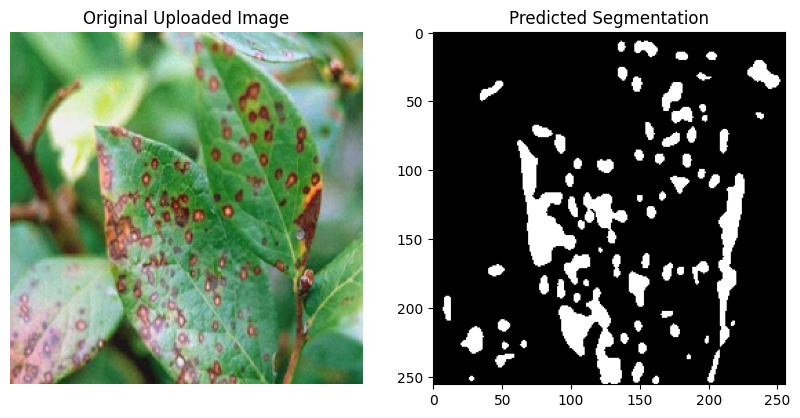

In [5]:
from google.colab import files
import io

# Make sure your trained_model variable exists from the previous training step
if 'trained_model' not in locals():
    print("Error: The 'trained_model' variable is not defined.")
    print("Please make sure you have run the training script first.")
else:
    # Upload the file
    

    
    image_path = "/kaggle/input/leaf-disease-segmentation-with-trainvalid-split/leaf_disease_segmentation/orig_data/train_images/00018.jpg"
    
    # Define the device
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    
    # Run the prediction and visualization
    predict_and_visualize(trained_model, image_path, device)
    

## pspnet model

Training with 2352 images, validating with 588 images.


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth
100%|██████████| 97.8M/97.8M [00:00<00:00, 184MB/s] 


Starting training on cuda...


Epoch 1/20 [Validate]: 100%|██████████| 74/74 [00:05<00:00, 13.75it/s, Loss=0.3015, Acc=89.76%]



Epoch [1/20] -> Train Loss: 0.4626, Train Acc: 80.80% | Val Loss: 0.3554, Val Acc: 89.76%
--------------------------------------------------------------------------------


Epoch 2/20 [Validate]: 100%|██████████| 74/74 [00:05<00:00, 13.77it/s, Loss=0.2431, Acc=91.64%]


... (33 outputs left out)

Epoch 19/20 [Validate]: 100%|██████████| 74/74 [00:05<00:00, 13.40it/s, Loss=0.1906, Acc=94.03%]



Epoch [19/20] -> Train Loss: 0.1809, Train Acc: 94.98% | Val Loss: 0.2050, Val Acc: 94.03%
--------------------------------------------------------------------------------


Epoch 20/20 [Validate]: 100%|██████████| 74/74 [00:05<00:00, 13.32it/s, Loss=0.2071, Acc=93.84%]


Epoch [20/20] -> Train Loss: 0.1824, Train Acc: 94.99% | Val Loss: 0.2138, Val Acc: 93.84%
--------------------------------------------------------------------------------
Visualizing model predictions...


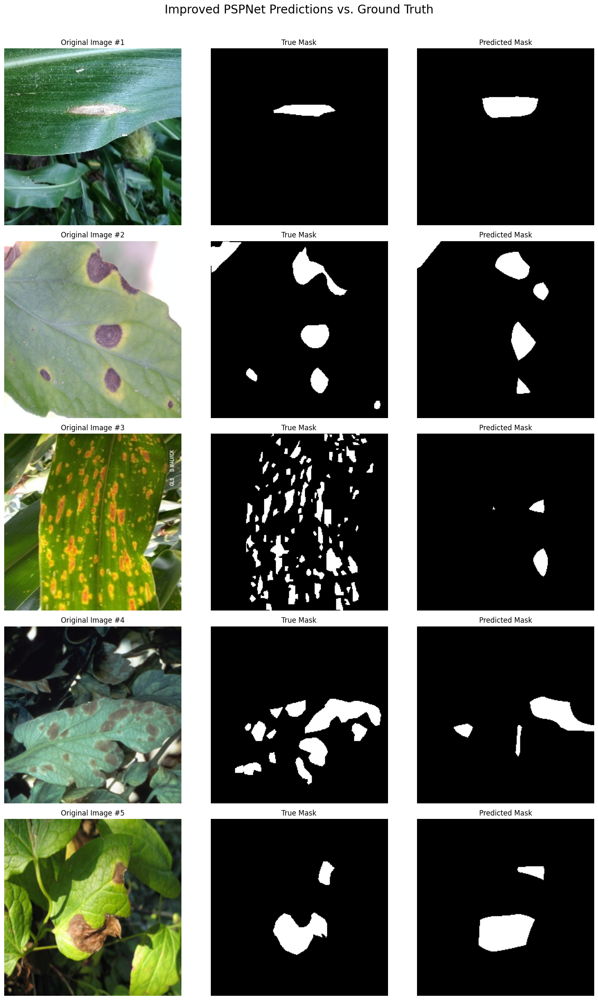

In [6]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms, models
from torch.optim.lr_scheduler import ReduceLROnPlateau
from PIL import Image
import matplotlib.pyplot as plt
from tqdm import tqdm
import warnings

warnings.filterwarnings("ignore")

# --- 1. NEW: Dice Loss Function ---
# This loss is much better for imbalanced segmentation tasks
class DiceLoss(nn.Module):
    def __init__(self, smooth=1.0):
        super(DiceLoss, self).__init__()
        self.smooth = smooth

    def forward(self, outputs, masks):
        outputs = F.softmax(outputs, dim=1)
        outputs = outputs[:, 1] # We only care about the "disease" class (class 1)
        masks = masks.float()

        intersection = (outputs * masks).sum()
        dice_coeff = (2. * intersection + self.smooth) / (outputs.sum() + masks.sum() + self.smooth)
        
        return 1 - dice_coeff # We want to minimize 1 - Dice

# --- 2. Model Definition (PSPNet - Same as before) ---
class PyramidPoolingModule(nn.Module):
    def __init__(self, in_channels, pool_sizes):
        super(PyramidPoolingModule, self).__init__()
        self.pool_layers = nn.ModuleList([
            nn.Sequential(
                nn.AdaptiveAvgPool2d(size),
                nn.Conv2d(in_channels, in_channels // len(pool_sizes), kernel_size=1, bias=False),
                nn.BatchNorm2d(in_channels // len(pool_sizes)),
                nn.ReLU(inplace=True)
            ) for size in pool_sizes
        ])

    def forward(self, x):
        h, w = x.shape[2], x.shape[3]
        features = [x] + [F.interpolate(layer(x), size=(h, w), mode='bilinear', align_corners=True) for layer in self.pool_layers]
        return torch.cat(features, dim=1)

class PSPNet(nn.Module):
    def __init__(self, n_classes, pool_sizes=(1, 2, 3, 6)):
        super(PSPNet, self).__init__()
        resnet = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        self.backbone = nn.Sequential(*list(resnet.children())[:-2])
        self.ppm = PyramidPoolingModule(in_channels=2048, pool_sizes=pool_sizes)
        self.final_conv = nn.Sequential(
            nn.Conv2d(4096, 512, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.1),
            nn.Conv2d(512, n_classes, kernel_size=1)
        )

    def forward(self, x):
        h, w = x.shape[2], x.shape[3]
        features = self.backbone(x)
        pooled_features = self.ppm(features)
        output = self.final_conv(pooled_features)
        return F.interpolate(output, size=(h, w), mode='bilinear', align_corners=True)

# --- 3. Custom Dataset Class (Same as before) ---
class LeafSegDataset(Dataset):
    def __init__(self, img_dir, mask_dir, transform=None):
        self.img_dir = img_dir
        self.mask_dir = mask_dir
        self.transform = transform
        self.img_files = sorted(os.listdir(img_dir))
        # This assumes mask filenames match image filenames
        self.mask_files = sorted(os.listdir(mask_dir))

    def __len__(self):
        return len(self.img_files)

    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.img_files[idx])
        mask_path = os.path.join(self.mask_dir, self.mask_files[idx])
        img = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path).convert("L")

        if self.transform:
            img = self.transform(img)
            mask = transforms.Resize((256, 256), interpolation=transforms.InterpolationMode.NEAREST)(mask)

        mask = np.array(mask, dtype=np.uint8)
        mask = np.where(mask == 38, 1, 0)
        mask = torch.tensor(mask, dtype=torch.long)
        return img, mask

# --- REVISED Training Function ---
def train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=10):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)
    print(f"Starting training on {device}...")
    
    for epoch in range(num_epochs):
        model.train()
        train_loss, train_correct, train_total = 0.0, 0, 0
        train_pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Train]")
        
        for images, masks in train_pbar:
            # THE FIX IS HERE: Correctly move both images and masks to the device
            images, masks = images.to(device), masks.to(device)
            
            outputs = model(images)
            loss = criterion(outputs, masks)
            
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            
            _, preds = torch.max(outputs, 1)
            train_total += masks.numel()
            train_correct += (preds == masks).sum().item()
            train_loss += loss.item() * images.size(0)
            train_pbar.set_postfix({'Loss': f"{loss.item():.4f}", 'Acc': f"{(100 * train_correct / train_total):.2f}%"})

        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        val_pbar = tqdm(val_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Validate]")
        
        with torch.no_grad():
            for images, masks in val_pbar:
                # THE FIX IS HERE AS WELL
                images, masks = images.to(device), masks.to(device)
                
                outputs = model(images)
                loss = criterion(outputs, masks)
                
                _, preds = torch.max(outputs, 1)
                val_total += masks.numel()
                val_correct += (preds == masks).sum().item()
                val_loss += loss.item() * images.size(0)
                val_pbar.set_postfix({'Loss': f"{loss.item():.4f}", 'Acc': f"{(100 * val_correct / val_total):.2f}%"})

        avg_train_loss = train_loss / len(train_loader.dataset)
        avg_val_loss = val_loss / len(val_loader.dataset)
        train_accuracy = 100 * train_correct / train_total
        val_accuracy = 100 * val_correct / val_total
        
        print(f"\nEpoch [{epoch+1}/{num_epochs}] -> Train Loss: {avg_train_loss:.4f}, Train Acc: {train_accuracy:.2f}% | Val Loss: {avg_val_loss:.4f}, Val Acc: {val_accuracy:.2f}%")
        
        scheduler.step(avg_val_loss)
        print("-" * 80)
        
    return model

def visualize_predictions(model, loader, device, num_images=5):
    # This function remains the same
    print("Visualizing model predictions...")
    model.eval()
    images, masks = next(iter(loader))
    images = images.to(device)
    with torch.no_grad():
        outputs = model(images); _, preds = torch.max(outputs, 1)
    images, preds = images.cpu(), preds.cpu()
    fig, axs = plt.subplots(num_images, 3, figsize=(15, num_images * 5))
    fig.suptitle("Improved PSPNet Predictions vs. Ground Truth", fontsize=20)
    for i in range(num_images):
        img = images[i].permute(1, 2, 0).numpy()
        mean=np.array([0.485,0.456,0.406]); std=np.array([0.229,0.224,0.225])
        img = std * img + mean; img = np.clip(img, 0, 1)
        axs[i, 0].imshow(img); axs[i, 0].set_title(f"Original Image #{i+1}"); axs[i, 0].axis('off')
        axs[i, 1].imshow(masks[i], cmap='gray'); axs[i, 1].set_title("True Mask"); axs[i, 1].axis('off')
        axs[i, 2].imshow(preds[i], cmap='gray'); axs[i, 2].set_title("Predicted Mask"); axs[i, 2].axis('off')
    plt.tight_layout(rect=[0, 0.03, 1, 0.97]); plt.show()

# --- 5. Main Execution Block with Improvements ---
# Configuration
IMG_DIR = "/kaggle/input/leaf-disease-segmentation-dataset/aug_data/aug_data/images"
MASK_DIR = "/kaggle/input/leaf-disease-segmentation-dataset/aug_data/aug_data/masks"
BATCH_SIZE = 8
LEARNING_RATE = 1e-4
NUM_EPOCHS = 20 # Increased epochs for better convergence

# Transforms with normalization
img_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# **IMPROVEMENT**: Use random_split for a more robust validation set
full_dataset = LeafSegDataset(IMG_DIR, MASK_DIR, transform=img_transform)
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])

print(f"Training with {len(train_dataset)} images, validating with {len(val_dataset)} images.")

# Create DataLoaders
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

# Initialize Model, Loss, and Optimizer
model = PSPNet(n_classes=2)
# **IMPROVEMENT**: Use DiceLoss
criterion = DiceLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
# **IMPROVEMENT**: Add a learning rate scheduler
scheduler = ReduceLROnPlateau(optimizer, 'min', patience=2, factor=0.1, verbose=True)

# Train the model with the new scheduler
trained_model = train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=NUM_EPOCHS)

# Visualize results
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
visualize_predictions(trained_model, val_loader, device=device, num_images=min(5, val_size))

## PSPNET V2

Training with 2352 images, validating with 588 images.
Starting PSPNet training on cuda...


Epoch 1/10 [Train]: 100%|██████████| 294/294 [00:43<00:00,  6.81it/s, Loss=0.4166]



Epoch [1/10] -> Train Loss: 0.4487 | Val Loss: 0.3544 | Val IoU: 0.4977 | Val Dice: 0.6577
--------------------------------------------------------------------------------


Epoch 2/10 [Train]: 100%|██████████| 294/294 [00:43<00:00,  6.79it/s, Loss=0.2806]



Epoch [2/10] -> Train Loss: 0.3254 | Val Loss: 0.2953 | Val IoU: 0.5624 | Val Dice: 0.7138
--------------------------------------------------------------------------------


Epoch 3/10 [Train]: 100%|██████████| 294/294 [00:43<00:00,  6.82it/s, Loss=0.3883]


... (11 outputs left out)

Epoch 9/10 [Train]: 100%|██████████| 294/294 [00:43<00:00,  6.80it/s, Loss=0.1657]



Epoch [9/10] -> Train Loss: 0.2115 | Val Loss: 0.2318 | Val IoU: 0.6372 | Val Dice: 0.7736
--------------------------------------------------------------------------------


Epoch 10/10 [Train]: 100%|██████████| 294/294 [00:43<00:00,  6.80it/s, Loss=0.2438]



Epoch [10/10] -> Train Loss: 0.2048 | Val Loss: 0.2264 | Val IoU: 0.6428 | Val Dice: 0.7777
--------------------------------------------------------------------------------

PSPNet training history saved to /kaggle/working/pspnet_history.pkl
PSPNet model weights saved to /kaggle/working/pspnet_model.pth
Visualizing model predictions...


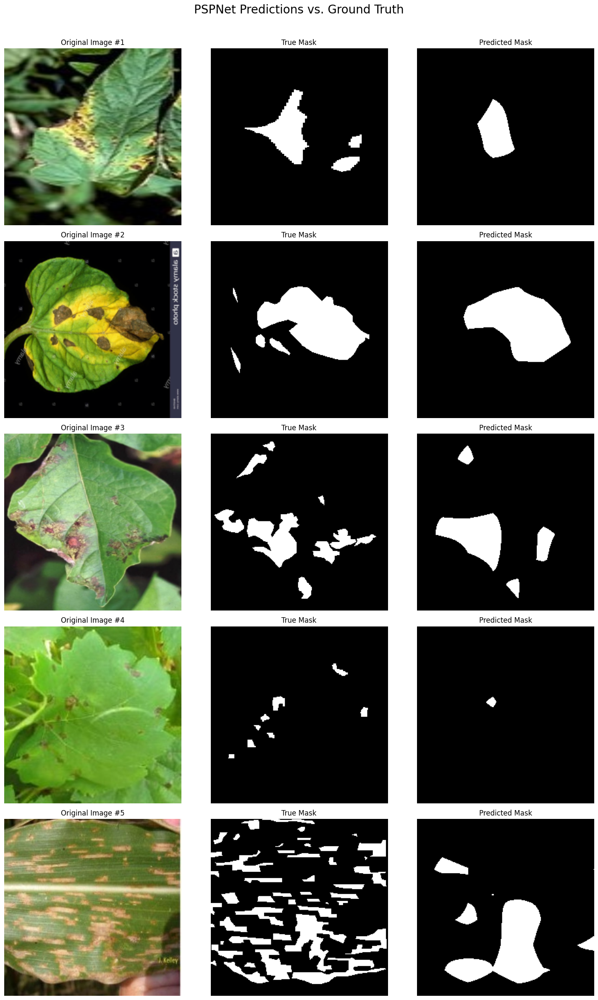

In [7]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms, models
from torch.optim.lr_scheduler import ReduceLROnPlateau
from PIL import Image
import matplotlib.pyplot as plt
from tqdm import tqdm
import pickle
import warnings

warnings.filterwarnings("ignore")

# --- 1. Dice Loss Function ---
class DiceLoss(nn.Module):
    def __init__(self, smooth=1.0):
        super(DiceLoss, self).__init__()
        self.smooth = smooth

    def forward(self, outputs, masks):
        outputs = F.softmax(outputs, dim=1)[:, 1]
        masks = masks.float()
        intersection = (outputs * masks).sum()
        dice_coeff = (2. * intersection + self.smooth) / (outputs.sum() + masks.sum() + self.smooth)
        return 1 - dice_coeff

# --- 2. Model Definition (PSPNet) ---
class PyramidPoolingModule(nn.Module):
    def __init__(self, in_channels, pool_sizes):
        super(PyramidPoolingModule, self).__init__()
        self.pool_layers = nn.ModuleList([
            nn.Sequential(
                nn.AdaptiveAvgPool2d(size),
                nn.Conv2d(in_channels, in_channels // len(pool_sizes), kernel_size=1, bias=False),
                nn.BatchNorm2d(in_channels // len(pool_sizes)),
                nn.ReLU(inplace=True)
            ) for size in pool_sizes
        ])

    def forward(self, x):
        h, w = x.shape[2], x.shape[3]
        features = [x] + [F.interpolate(layer(x), size=(h, w), mode='bilinear', align_corners=True) for layer in self.pool_layers]
        return torch.cat(features, dim=1)

class PSPNet(nn.Module):
    def __init__(self, n_classes, pool_sizes=(1, 2, 3, 6)):
        super(PSPNet, self).__init__()
        resnet = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        self.backbone = nn.Sequential(*list(resnet.children())[:-2])
        self.ppm = PyramidPoolingModule(in_channels=2048, pool_sizes=pool_sizes)
        self.final_conv = nn.Sequential(
            nn.Conv2d(4096, 512, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.1),
            nn.Conv2d(512, n_classes, kernel_size=1)
        )

    def forward(self, x):
        h, w = x.shape[2], x.shape[3]
        features = self.backbone(x)
        pooled_features = self.ppm(features)
        output = self.final_conv(pooled_features)
        return F.interpolate(output, size=(h, w), mode='bilinear', align_corners=True)

# --- 3. Custom Dataset Classes ---
class FullLeafDataset(Dataset):
    def __init__(self, img_dir, mask_dir):
        self.img_dir = img_dir
        self.mask_dir = mask_dir
        self.img_files = sorted(os.listdir(img_dir))
        self.mask_files = sorted(os.listdir(mask_dir))

    def __len__(self):
        return len(self.img_files)

    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.img_files[idx])
        mask_path = os.path.join(self.mask_dir, self.mask_files[idx])
        img = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path).convert("L")
        mask = transforms.functional.resize(mask, (256, 256), interpolation=transforms.InterpolationMode.NEAREST)
        mask = np.array(mask, dtype=np.uint8)
        mask = np.where(mask == 38, 1, 0)
        mask = torch.tensor(mask, dtype=torch.long)
        return img, mask

class LeafSegDataset(Dataset):
    def __init__(self, subset, transform=None):
        self.subset = subset
        self.transform = transform

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        img, mask = self.subset[idx]
        if self.transform:
            img = self.transform(img)
        return img, mask

# --- 4. Training Loop that returns history ---
def train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=15):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)
    history = {'train_loss': [], 'val_loss': [], 'val_iou': [], 'val_dice': []}
    
    print(f"Starting PSPNet training on {device}...")
    for epoch in range(num_epochs):
        model.train()
        train_loss = 0.0
        train_pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Train]")
        for images, masks in train_pbar:
            images, masks = images.to(device), masks.to(device)
            outputs = model(images); loss = criterion(outputs, masks)
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            train_loss += loss.item() * images.size(0)
            train_pbar.set_postfix({'Loss': f"{loss.item():.4f}"})

        model.eval()
        val_loss, val_iou, val_dice = 0.0, 0.0, 0.0
        with torch.no_grad():
            for images, masks in val_loader:
                images, masks = images.to(device), masks.to(device)
                outputs = model(images); loss = criterion(outputs, masks)
                val_loss += loss.item() * images.size(0)
                preds = torch.argmax(outputs, dim=1)
                intersection = torch.logical_and(masks, preds).sum()
                union = torch.logical_or(masks, preds).sum()
                val_iou += ((intersection + 1e-6) / (union + 1e-6)).item()
                val_dice += ((2. * intersection + 1e-6) / (masks.sum() + preds.sum() + 1e-6)).item()

        avg_train_loss = train_loss / len(train_loader.dataset)
        avg_val_loss = val_loss / len(val_loader.dataset)
        avg_val_iou = val_iou / len(val_loader)
        avg_val_dice = val_dice / len(val_loader)
        
        history['train_loss'].append(avg_train_loss)
        history['val_loss'].append(avg_val_loss)
        history['val_iou'].append(avg_val_iou)
        history['val_dice'].append(avg_val_dice)
        
        print(f"\nEpoch [{epoch+1}/{num_epochs}] -> Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Val IoU: {avg_val_iou:.4f} | Val Dice: {avg_val_dice:.4f}")
        scheduler.step(avg_val_loss)
        print("-" * 80)
        
    return model, history

# --- 5. Visualization Function ---
def visualize_predictions(model, loader, device, num_images=5):
    print("Visualizing model predictions...")
    model.eval()
    images, masks = next(iter(loader))
    images = images.to(device)
    with torch.no_grad():
        outputs = model(images); _, preds = torch.max(outputs, 1)

    images, preds = images.cpu(), preds.cpu()
    fig, axs = plt.subplots(num_images, 3, figsize=(15, num_images * 5))
    fig.suptitle("PSPNet Predictions vs. Ground Truth", fontsize=20)
    for i in range(num_images):
        img = images[i].permute(1, 2, 0).numpy()
        mean=np.array([0.485,0.456,0.406]); std=np.array([0.229,0.224,0.225])
        img = std * img + mean; img = np.clip(img, 0, 1)
        axs[i, 0].imshow(img); axs[i, 0].set_title(f"Original Image #{i+1}"); axs[i, 0].axis('off')
        axs[i, 1].imshow(masks[i], cmap='gray'); axs[i, 1].set_title("True Mask"); axs[i, 1].axis('off')
        axs[i, 2].imshow(preds[i], cmap='gray'); axs[i, 2].set_title("Predicted Mask"); axs[i, 2].axis('off')
    plt.tight_layout(rect=[0, 0.03, 1, 0.97]); plt.show()

# --- 6. Main Execution ---
# Configuration
IMG_DIR = "/kaggle/input/leaf-disease-segmentation-dataset/aug_data/aug_data/images"
MASK_DIR = "/kaggle/input/leaf-disease-segmentation-dataset/aug_data/aug_data/masks"
BATCH_SIZE = 8
LEARNING_RATE = 1e-4
NUM_EPOCHS = 10

# Image transforms with normalization for the pre-trained backbone
img_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Create the full dataset and then split it randomly
full_dataset = FullLeafDataset(IMG_DIR, MASK_DIR)
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_subset, val_subset = random_split(full_dataset, [train_size, val_size])

train_dataset = LeafSegDataset(train_subset, transform=img_transform)
val_dataset = LeafSegDataset(val_subset, transform=img_transform)
print(f"Training with {len(train_dataset)} images, validating with {len(val_dataset)} images.")

# Create DataLoaders
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

# Initialize Model, Loss, and Optimizer
model = PSPNet(n_classes=2)
criterion = DiceLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
scheduler = ReduceLROnPlateau(optimizer, 'min', patience=3, factor=0.1, verbose=True)

# Train the model and get the history
trained_model, history = train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=NUM_EPOCHS)

# --- NEW: Save the history and model weights ---
SAVE_DIR = "/kaggle/working/"
# Save history
history_filename = "pspnet_history.pkl"
history_path = os.path.join(SAVE_DIR, history_filename)
with open(history_path, 'wb') as f:
    pickle.dump(history, f)
print(f"\nPSPNet training history saved to {history_path}")

# Save model weights
model_filename = "pspnet_model.pth"
model_path = os.path.join(SAVE_DIR, model_filename)
torch.save(trained_model.state_dict(), model_path)
print(f"PSPNet model weights saved to {model_path}")

# Visualize results for the last trained model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
visualize_predictions(trained_model, val_loader, device=device, num_images=min(5, len(val_dataset)))

## Deeplabv3+

Training with 2352 images, validating with 588 images.


Downloading: "https://download.pytorch.org/models/deeplabv3_resnet50_coco-cd0a2569.pth" to /root/.cache/torch/hub/checkpoints/deeplabv3_resnet50_coco-cd0a2569.pth
100%|██████████| 161M/161M [00:00<00:00, 201MB/s]  


Starting training on cuda...


Epoch 1/5 [Validate]: 100%|██████████| 74/74 [00:18<00:00,  4.10it/s, Loss=0.4559]



Epoch [1/5] -> Train Loss: 0.5468 | Val Loss: 0.2511
--------------------------------------------------------------------------------


Epoch 2/5 [Validate]: 100%|██████████| 74/74 [00:18<00:00,  4.09it/s, Loss=0.3586]


... (3 outputs left out)

Epoch 4/5 [Validate]: 100%|██████████| 74/74 [00:18<00:00,  4.09it/s, Loss=0.2599]



Epoch [4/5] -> Train Loss: 0.2341 | Val Loss: 0.1690
--------------------------------------------------------------------------------


Epoch 5/5 [Validate]: 100%|██████████| 74/74 [00:18<00:00,  4.08it/s, Loss=0.1580]


Epoch [5/5] -> Train Loss: 0.2072 | Val Loss: 0.1565
--------------------------------------------------------------------------------
Visualizing model predictions...


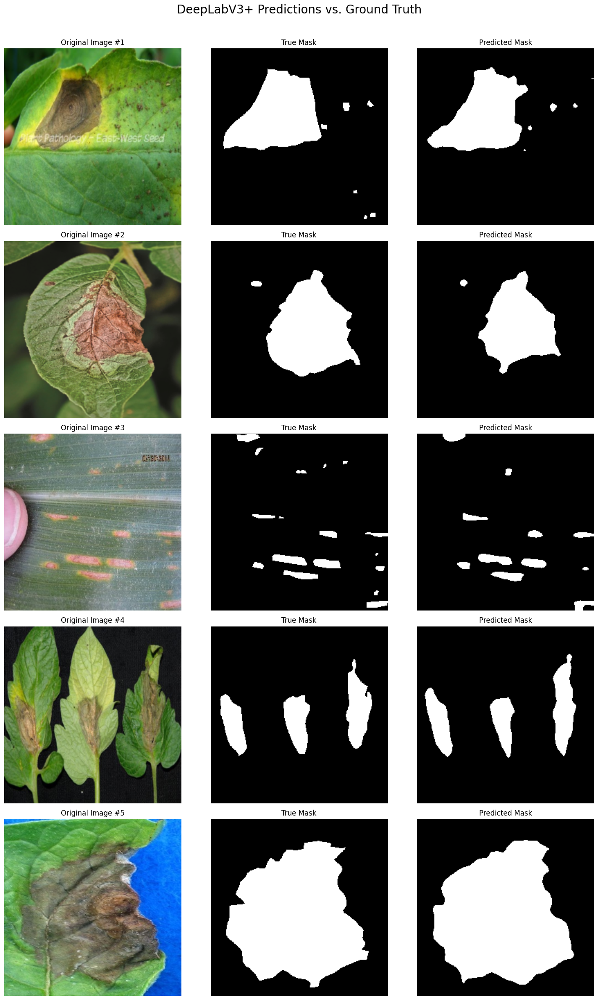

In [8]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms, models
from torch.optim.lr_scheduler import ReduceLROnPlateau
from PIL import Image
import matplotlib.pyplot as plt
from tqdm import tqdm
import warnings

# Suppress minor warnings for a cleaner output
warnings.filterwarnings("ignore")

# --- 1. Dice Loss Function ---
# This loss function is highly effective for imbalanced segmentation tasks.
class DiceLoss(nn.Module):
    def __init__(self, smooth=1.0):
        super(DiceLoss, self).__init__()
        self.smooth = smooth

    def forward(self, outputs, masks):
        # The 'outputs' from torchvision's DeepLabV3 are a dict. We need the 'out' key.
        outputs = outputs['out']
        # Apply softmax to get probabilities for each class
        outputs = F.softmax(outputs, dim=1)
        # We only care about the "disease" class (class 1)
        outputs = outputs[:, 1]
        masks = masks.float()

        intersection = (outputs * masks).sum()
        dice_coeff = (2. * intersection + self.smooth) / (outputs.sum() + masks.sum() + self.smooth)
        
        # We want to minimize (1 - Dice Coefficient), so the model learns to maximize the Dice score.
        return 1 - dice_coeff

# --- 2. Model Definition Function ---
def get_deeplabv3_model(n_classes=2):
    """
    Loads a pre-trained DeepLabV3+ model from torchvision and replaces the 
    classifier head to match the number of classes in our task.
    """
    # Load a model pre-trained on the COCO dataset
    model = models.segmentation.deeplabv3_resnet50(weights=models.segmentation.DeepLabV3_ResNet50_Weights.DEFAULT)
    
    # Replace the main classifier's final layer
    in_channels_classifier = model.classifier[4].in_channels
    model.classifier[4] = nn.Conv2d(in_channels_classifier, n_classes, kernel_size=1)
    
    # (Optional but good practice) Replace the auxiliary classifier's final layer
    in_channels_aux = model.aux_classifier[4].in_channels
    model.aux_classifier[4] = nn.Conv2d(in_channels_aux, n_classes, kernel_size=1)
    
    return model

# --- 3. Custom Dataset Classes ---
# This is the base dataset that loads raw data from disk
class FullLeafDataset(Dataset):
    def __init__(self, img_dir, mask_dir):
        self.img_dir = img_dir
        self.mask_dir = mask_dir
        self.img_files = sorted(os.listdir(img_dir))
        self.mask_files = sorted(os.listdir(mask_dir))

    def __len__(self):
        return len(self.img_files)

    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.img_files[idx])
        mask_path = os.path.join(self.mask_dir, self.mask_files[idx])
        
        img = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path).convert("L")

        # Process the mask to the correct format and size
        mask = transforms.functional.resize(mask, (256, 256), interpolation=transforms.InterpolationMode.NEAREST)
        mask = np.array(mask, dtype=np.uint8)
        mask = np.where(mask == 38, 1, 0) # Remap {0, 38} to {0, 1}
        mask = torch.tensor(mask, dtype=torch.long)
        
        # Return the raw PIL image and the processed mask
        return img, mask

# This wrapper class applies the final image transformations
class LeafSegDataset(Dataset):
    def __init__(self, subset, transform=None):
        self.subset = subset
        self.transform = transform

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        img, mask = self.subset[idx]
        if self.transform:
            img = self.transform(img)
        return img, mask

# --- 4. Training and Visualization Functions ---
def train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=15):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)
    print(f"Starting training on {device}...")
    
    for epoch in range(num_epochs):
        model.train()
        train_loss = 0.0
        train_pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Train]")
        
        for images, masks in train_pbar:
            images, masks = images.to(device), masks.to(device)
            outputs = model(images)
            loss = criterion(outputs, masks)
            
            # The official model has an auxiliary loss which can aid training
            if 'aux' in outputs:
                loss += 0.4 * criterion({'out': outputs['aux']}, masks)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * images.size(0)
            train_pbar.set_postfix({'Loss': f"{loss.item():.4f}"})

        model.eval()
        val_loss = 0.0
        val_pbar = tqdm(val_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Validate]")
        with torch.no_grad():
            for images, masks in val_pbar:
                images, masks = images.to(device), masks.to(device)
                outputs = model(images)
                loss = criterion(outputs, masks)
                val_loss += loss.item() * images.size(0)
                val_pbar.set_postfix({'Loss': f"{loss.item():.4f}"})

        avg_train_loss = train_loss / len(train_loader.dataset)
        avg_val_loss = val_loss / len(val_loader.dataset)
        
        print(f"\nEpoch [{epoch+1}/{num_epochs}] -> Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")
        scheduler.step(avg_val_loss) # Update learning rate based on validation loss
        print("-" * 80)
        
    return model

def visualize_predictions(model, loader, device, num_images=5):
    print("Visualizing model predictions...")
    model.eval()
    images, masks = next(iter(loader))
    images = images.to(device)
    
    with torch.no_grad():
        outputs = model(images)['out']
        _, preds = torch.max(outputs, 1)

    images = images.cpu()
    preds = preds.cpu()
    
    fig, axs = plt.subplots(num_images, 3, figsize=(15, num_images * 5))
    fig.suptitle("DeepLabV3+ Predictions vs. Ground Truth", fontsize=20)
    
    for i in range(num_images):
        img = images[i].permute(1, 2, 0).numpy()
        # Un-normalize the image for correct visualization
        mean = np.array([0.485, 0.456, 0.406])
        std = np.array([0.229, 0.224, 0.225])
        img = std * img + mean
        img = np.clip(img, 0, 1)
        
        axs[i, 0].imshow(img)
        axs[i, 0].set_title(f"Original Image #{i+1}")
        axs[i, 0].axis('off')

        axs[i, 1].imshow(masks[i], cmap='gray')
        axs[i, 1].set_title("True Mask")
        axs[i, 1].axis('off')

        axs[i, 2].imshow(preds[i], cmap='gray')
        axs[i, 2].set_title("Predicted Mask")
        axs[i, 2].axis('off')
        
    plt.tight_layout(rect=[0, 0.03, 1, 0.97])
    plt.show()

# --- 5. Main Execution Block ---
# Configuration
IMG_DIR = "/kaggle/input/leaf-disease-segmentation-dataset/aug_data/aug_data/images"
MASK_DIR = "/kaggle/input/leaf-disease-segmentation-dataset/aug_data/aug_data/masks"
BATCH_SIZE = 8
LEARNING_RATE = 1e-4
NUM_EPOCHS = 5 # Increased epochs for better results

# Image transforms, including resizing and normalization
img_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Create the full dataset and then split it randomly
full_dataset = FullLeafDataset(IMG_DIR, MASK_DIR)
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_subset, val_subset = random_split(full_dataset, [train_size, val_size])

# Apply the image transforms using the wrapper dataset
train_dataset = LeafSegDataset(train_subset, transform=img_transform)
val_dataset = LeafSegDataset(val_subset, transform=img_transform)

print(f"Training with {len(train_dataset)} images, validating with {len(val_dataset)} images.")

# Create DataLoaders
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

# Initialize Model, Loss, and Optimizer
model = get_deeplabv3_model(n_classes=2)
criterion = DiceLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
scheduler = ReduceLROnPlateau(optimizer, 'min', patience=2, factor=0.1, verbose=True)

# Train the model
trained_model = train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=NUM_EPOCHS)

# Visualize results on the validation set
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
visualize_predictions(trained_model, val_loader, device=device, num_images=min(5, len(val_dataset)))

## DeepLabV3+ v2

Training with 2352 images, validating with 588 images.
Starting DeepLabV3+ training on cuda...


Epoch 1/10 [Train]: 100%|██████████| 294/294 [03:20<00:00,  1.47it/s, Loss=0.3435]



Epoch [1/10] -> Train Loss: 0.5338 | Val Loss: 0.2421 | Val IoU: 0.6401 | Val Dice: 0.7768
--------------------------------------------------------------------------------


Epoch 2/10 [Train]: 100%|██████████| 294/294 [03:20<00:00,  1.47it/s, Loss=0.3075]



Epoch [2/10] -> Train Loss: 0.3293 | Val Loss: 0.1862 | Val IoU: 0.7035 | Val Dice: 0.8238
--------------------------------------------------------------------------------


Epoch 3/10 [Train]: 100%|██████████| 294/294 [03:20<00:00,  1.47it/s, Loss=0.2097]


... (11 outputs left out)

Epoch 9/10 [Train]: 100%|██████████| 294/294 [03:20<00:00,  1.47it/s, Loss=0.1288]



Epoch [9/10] -> Train Loss: 0.1483 | Val Loss: 0.1300 | Val IoU: 0.7770 | Val Dice: 0.8729
--------------------------------------------------------------------------------


Epoch 10/10 [Train]: 100%|██████████| 294/294 [03:20<00:00,  1.47it/s, Loss=0.1273]



Epoch [10/10] -> Train Loss: 0.1414 | Val Loss: 0.1305 | Val IoU: 0.7766 | Val Dice: 0.8724
--------------------------------------------------------------------------------

DeepLabV3+ training history saved to /kaggle/working/deeplabv3_history.pkl
DeepLabV3+ model weights saved to /kaggle/working/deeplabv3_model.pth
Visualizing model predictions...


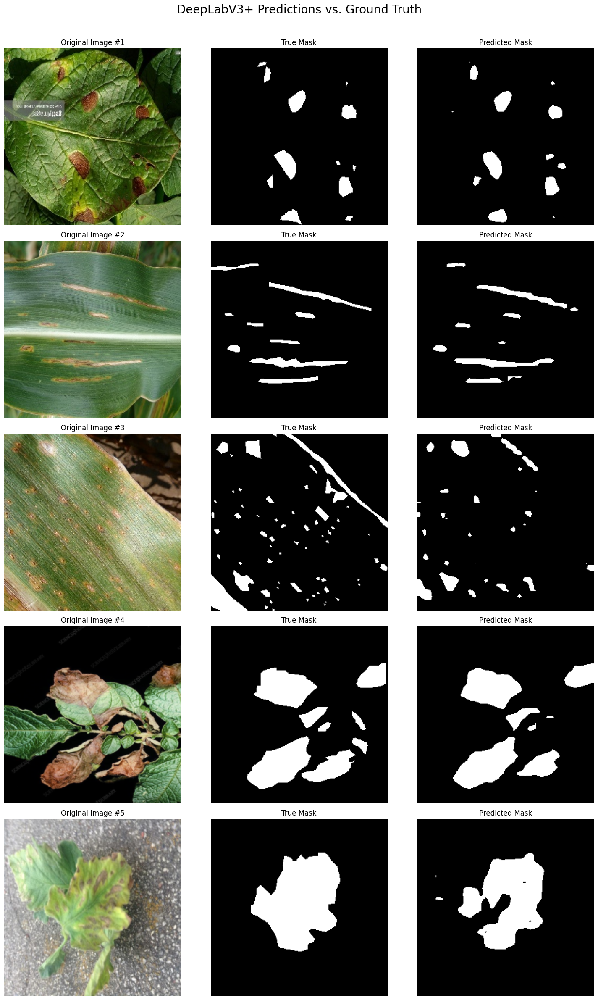

In [9]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms, models
from torch.optim.lr_scheduler import ReduceLROnPlateau
from PIL import Image
import matplotlib.pyplot as plt
from tqdm import tqdm
import pickle
import warnings

warnings.filterwarnings("ignore")

# --- 1. Dice Loss Function ---
class DiceLoss(nn.Module):
    def __init__(self, smooth=1.0):
        super(DiceLoss, self).__init__()
        self.smooth = smooth

    def forward(self, outputs, masks):
        # The 'outputs' from torchvision's DeepLabV3 are a dict. We need the 'out' key.
        outputs = outputs['out']
        outputs = F.softmax(outputs, dim=1)[:, 1]
        masks = masks.float()

        intersection = (outputs * masks).sum()
        dice_coeff = (2. * intersection + self.smooth) / (outputs.sum() + masks.sum() + self.smooth)
        return 1 - dice_coeff

# --- 2. Model Definition Function ---
def get_deeplabv3_model(n_classes=2):
    model = models.segmentation.deeplabv3_resnet50(weights=models.segmentation.DeepLabV3_ResNet50_Weights.DEFAULT)
    model.classifier[4] = nn.Conv2d(model.classifier[4].in_channels, n_classes, kernel_size=1)
    model.aux_classifier[4] = nn.Conv2d(model.aux_classifier[4].in_channels, n_classes, kernel_size=1)
    return model

# --- 3. Custom Dataset Classes ---
class FullLeafDataset(Dataset):
    def __init__(self, img_dir, mask_dir):
        self.img_dir = img_dir
        self.mask_dir = mask_dir
        self.img_files = sorted(os.listdir(img_dir))
        self.mask_files = sorted(os.listdir(mask_dir))

    def __len__(self):
        return len(self.img_files)

    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.img_files[idx])
        mask_path = os.path.join(self.mask_dir, self.mask_files[idx])
        img = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path).convert("L")
        mask = transforms.functional.resize(mask, (256, 256), interpolation=transforms.InterpolationMode.NEAREST)
        mask = np.array(mask, dtype=np.uint8)
        mask = np.where(mask == 38, 1, 0)
        mask = torch.tensor(mask, dtype=torch.long)
        return img, mask

class LeafSegDataset(Dataset):
    def __init__(self, subset, transform=None):
        self.subset = subset
        self.transform = transform

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        img, mask = self.subset[idx]
        if self.transform:
            img = self.transform(img)
        return img, mask

# --- 4. Training Loop that returns history ---
def train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=15):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)
    history = {'train_loss': [], 'val_loss': [], 'val_iou': [], 'val_dice': []}
    
    print(f"Starting DeepLabV3+ training on {device}...")
    for epoch in range(num_epochs):
        model.train()
        train_loss = 0.0
        train_pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Train]")
        for images, masks in train_pbar:
            images, masks = images.to(device), masks.to(device)
            outputs = model(images)
            loss = criterion(outputs, masks)
            if 'aux' in outputs:
                loss += 0.4 * criterion({'out': outputs['aux']}, masks)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * images.size(0)
            train_pbar.set_postfix({'Loss': f"{loss.item():.4f}"})

        model.eval()
        val_loss, val_iou, val_dice = 0.0, 0.0, 0.0
        with torch.no_grad():
            for images, masks in val_loader:
                images, masks = images.to(device), masks.to(device)
                outputs = model(images)
                loss = criterion(outputs, masks)
                val_loss += loss.item() * images.size(0)
                
                preds = torch.argmax(outputs['out'], dim=1)
                intersection = torch.logical_and(masks, preds).sum()
                union = torch.logical_or(masks, preds).sum()
                val_iou += ((intersection + 1e-6) / (union + 1e-6)).item()
                val_dice += ((2. * intersection + 1e-6) / (masks.sum() + preds.sum() + 1e-6)).item()

        avg_train_loss = train_loss / len(train_loader.dataset)
        avg_val_loss = val_loss / len(val_loader.dataset)
        avg_val_iou = val_iou / len(val_loader)
        avg_val_dice = val_dice / len(val_loader)
        
        history['train_loss'].append(avg_train_loss)
        history['val_loss'].append(avg_val_loss)
        history['val_iou'].append(avg_val_iou)
        history['val_dice'].append(avg_val_dice)
        
        print(f"\nEpoch [{epoch+1}/{num_epochs}] -> Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Val IoU: {avg_val_iou:.4f} | Val Dice: {avg_val_dice:.4f}")
        scheduler.step(avg_val_loss)
        print("-" * 80)
        
    return model, history

# --- 5. Visualization Function ---
def visualize_predictions(model, loader, device, num_images=5):
    print("Visualizing model predictions...")
    model.eval()
    images, masks = next(iter(loader))
    images = images.to(device)
    with torch.no_grad():
        outputs = model(images)['out']
        _, preds = torch.max(outputs, 1)

    images, preds = images.cpu(), preds.cpu()
    fig, axs = plt.subplots(num_images, 3, figsize=(15, num_images * 5))
    fig.suptitle("DeepLabV3+ Predictions vs. Ground Truth", fontsize=20)
    for i in range(num_images):
        img = images[i].permute(1, 2, 0).numpy()
        mean=np.array([0.485,0.456,0.406]); std=np.array([0.229,0.224,0.225])
        img = std * img + mean; img = np.clip(img, 0, 1)
        axs[i, 0].imshow(img); axs[i, 0].set_title(f"Original Image #{i+1}"); axs[i, 0].axis('off')
        axs[i, 1].imshow(masks[i], cmap='gray'); axs[i, 1].set_title("True Mask"); axs[i, 1].axis('off')
        axs[i, 2].imshow(preds[i], cmap='gray'); axs[i, 2].set_title("Predicted Mask"); axs[i, 2].axis('off')
    plt.tight_layout(rect=[0, 0.03, 1, 0.97]); plt.show()

# --- 6. Main Execution ---
# Configuration
IMG_DIR = "/kaggle/input/leaf-disease-segmentation-dataset/aug_data/aug_data/images"
MASK_DIR = "/kaggle/input/leaf-disease-segmentation-dataset/aug_data/aug_data/masks"
BATCH_SIZE = 8
LEARNING_RATE = 1e-4
NUM_EPOCHS = 10

# Image transforms with normalization for the pre-trained backbone
img_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Create the full dataset and then split it randomly
full_dataset = FullLeafDataset(IMG_DIR, MASK_DIR)
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_subset, val_subset = random_split(full_dataset, [train_size, val_size])

train_dataset = LeafSegDataset(train_subset, transform=img_transform)
val_dataset = LeafSegDataset(val_subset, transform=img_transform)
print(f"Training with {len(train_dataset)} images, validating with {len(val_dataset)} images.")

# Create DataLoaders
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

# Initialize Model, Loss, and Optimizer
model = get_deeplabv3_model(n_classes=2)
criterion = DiceLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
scheduler = ReduceLROnPlateau(optimizer, 'min', patience=3, factor=0.1, verbose=True)

# Train the model and get the history
trained_model, history = train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=NUM_EPOCHS)

# --- NEW: Save the history and model weights ---
SAVE_DIR = "/kaggle/working/"
# Save history
history_filename = "deeplabv3_history.pkl"
history_path = os.path.join(SAVE_DIR, history_filename)
with open(history_path, 'wb') as f:
    pickle.dump(history, f)
print(f"\nDeepLabV3+ training history saved to {history_path}")

# Save model weights
model_filename = "deeplabv3_model.pth"
model_path = os.path.join(SAVE_DIR, model_filename)
torch.save(trained_model.state_dict(), model_path)
print(f"DeepLabV3+ model weights saved to {model_path}")

# Visualize results
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
visualize_predictions(trained_model, val_loader, device=device, num_images=min(5, len(val_dataset)))

## SegFormer

In [10]:
!pip install -q transformers evaluate accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.6/193.6 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.5 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 39.8 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 27.9 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 20.2 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.4 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 4.5 MB/s eta 0:00:0000:0100:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 3.7 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 8.6 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 6.7 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

2026-11-21 21:44:44.092108: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1795297484.294405      40 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1795297484.359193      40 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


Training with 2352 images, validating with 588 images.


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/15.0M [00:00<?, ?B/s]

Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/segformer-b0-finetuned-ade-512-512 and are newly initialized because the shapes did not match:
- decode_head.classifier.bias: found shape torch.Size([150]) in the checkpoint and torch.Size([2]) in the model instantiated
- decode_head.classifier.weight: found shape torch.Size([150, 256, 1, 1]) in the checkpoint and torch.Size([2, 256, 1, 1]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Starting training on cuda...


... (7 outputs left out)


Epoch [4/5] -> Train Loss: 0.1561 | Val Loss: 0.1345
--------------------------------------------------------------------------------


Epoch 5/5 [Validate]: 100%|██████████| 147/147 [00:11<00:00, 13.36it/s, Loss=0.1359]


Epoch [5/5] -> Train Loss: 0.1374 | Val Loss: 0.1243
--------------------------------------------------------------------------------
Visualizing model predictions...


IndexError: index 4 is out of bounds for dimension 0 with size 4

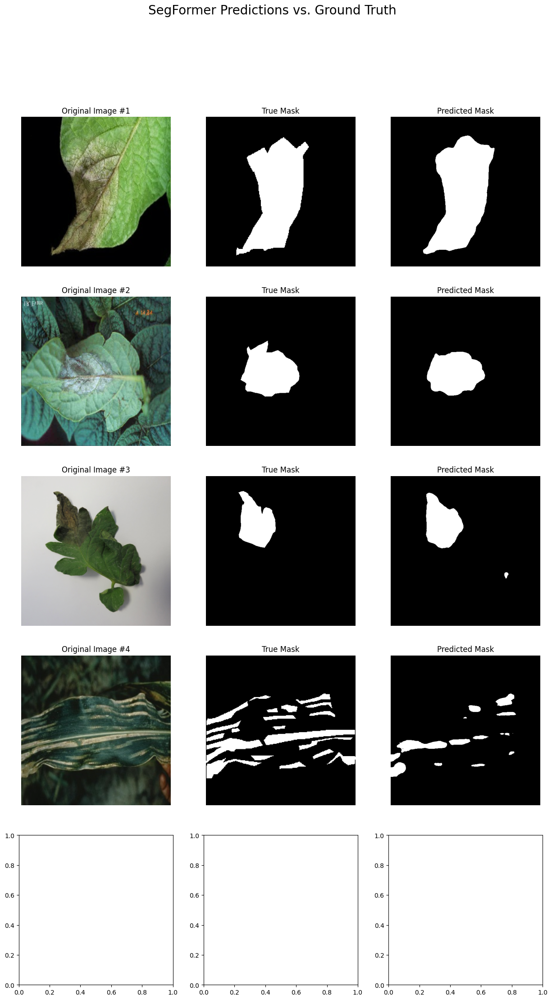

In [11]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
from PIL import Image
import matplotlib.pyplot as plt
from tqdm import tqdm
from transformers import SegformerForSemanticSegmentation
import warnings

warnings.filterwarnings("ignore")

# --- 1. Model Definition Function ---
def get_segformer_model(n_classes=2):
    """
    Loads a pre-trained SegFormer model from Hugging Face and adapts its
    classification head for our 2-class (background/disease) problem.
    """
    # Define the labels for our specific problem
    id2label = {0: "background", 1: "disease"}
    label2id = {label: id for id, label in id2label.items()}
    
    # Load a pre-trained SegFormer model (b0 is the smallest and fastest)
    model = SegformerForSemanticSegmentation.from_pretrained(
        "nvidia/segformer-b0-finetuned-ade-512-512",
        num_labels=n_classes,
        id2label=id2label,
        label2id=label2id,
        ignore_mismatched_sizes=True # This is important for transfer learning
    )
    return model

# --- 2. Custom Dataset Classes (Same as before) ---
class FullLeafDataset(Dataset):
    def __init__(self, img_dir, mask_dir):
        self.img_dir = img_dir
        self.mask_dir = mask_dir
        self.img_files = sorted(os.listdir(img_dir))
        self.mask_files = sorted(os.listdir(mask_dir))

    def __len__(self):
        return len(self.img_files)

    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.img_files[idx])
        mask_path = os.path.join(self.mask_dir, self.mask_files[idx])
        img = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path).convert("L")
        mask = transforms.functional.resize(mask, (512, 512), interpolation=transforms.InterpolationMode.NEAREST)
        mask = np.array(mask, dtype=np.uint8)
        mask = np.where(mask == 38, 1, 0)
        mask = torch.tensor(mask, dtype=torch.long)
        return img, mask

class LeafSegDataset(Dataset):
    def __init__(self, subset, transform=None):
        self.subset = subset
        self.transform = transform

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        img, mask = self.subset[idx]
        if self.transform:
            img = self.transform(img)
        return img, mask

# --- 3. Training and Visualization Functions (Updated for SegFormer) ---
def train_model(model, train_loader, val_loader, optimizer, scheduler, num_epochs=15):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)
    print(f"Starting training on {device}...")
    
    for epoch in range(num_epochs):
        model.train()
        train_loss = 0.0
        train_pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Train]")
        
        for images, masks in train_pbar:
            images, masks = images.to(device), masks.to(device)
            
            # Get outputs and loss directly from the model
            outputs = model(pixel_values=images, labels=masks)
            loss = outputs.loss
            
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            
            train_loss += loss.item() * images.size(0)
            train_pbar.set_postfix({'Loss': f"{loss.item():.4f}"})

        model.eval()
        val_loss = 0.0
        val_pbar = tqdm(val_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Validate]")
        with torch.no_grad():
            for images, masks in val_pbar:
                images, masks = images.to(device), masks.to(device)
                outputs = model(pixel_values=images, labels=masks)
                loss = outputs.loss
                val_loss += loss.item() * images.size(0)
                val_pbar.set_postfix({'Loss': f"{loss.item():.4f}"})

        avg_train_loss = train_loss / len(train_loader.dataset)
        avg_val_loss = val_loss / len(val_loader.dataset)
        
        print(f"\nEpoch [{epoch+1}/{num_epochs}] -> Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")
        scheduler.step(avg_val_loss)
        print("-" * 80)
        
    return model

def visualize_predictions(model, loader, device, num_images=5):
    print("Visualizing model predictions...")
    model.eval()
    images, masks = next(iter(loader))
    images = images.to(device)
    
    with torch.no_grad():
        outputs = model(pixel_values=images)
        logits = outputs.logits # Logits are B, C, H/4, W/4
        
        # Upsample logits to the original mask size
        upsampled_logits = F.interpolate(
            logits,
            size=masks.shape[-2:], # (H, W)
            mode='bilinear',
            align_corners=False
        )
        _, preds = torch.max(upsampled_logits, 1)

    images, preds = images.cpu(), preds.cpu()
    
    fig, axs = plt.subplots(num_images, 3, figsize=(15, num_images * 5))
    fig.suptitle("SegFormer Predictions vs. Ground Truth", fontsize=20)
    
    for i in range(num_images):
        img = images[i].permute(1, 2, 0).numpy()
        mean = np.array([0.485, 0.456, 0.406]); std = np.array([0.229, 0.224, 0.225])
        img = std * img + mean; img = np.clip(img, 0, 1)
        
        axs[i, 0].imshow(img); axs[i, 0].set_title(f"Original Image #{i+1}"); axs[i, 0].axis('off')
        axs[i, 1].imshow(masks[i], cmap='gray'); axs[i, 1].set_title("True Mask"); axs[i, 1].axis('off')
        axs[i, 2].imshow(preds[i], cmap='gray'); axs[i, 2].set_title("Predicted Mask"); axs[i, 2].axis('off')
        
    plt.tight_layout(rect=[0, 0.03, 1, 0.97]); plt.show()

# --- 4. Main Execution Block ---
# Configuration
IMG_DIR = "/kaggle/input/leaf-disease-segmentation-dataset/aug_data/aug_data/images"
MASK_DIR = "/kaggle/input/leaf-disease-segmentation-dataset/aug_data/aug_data/masks"
IMAGE_SIZE = 512 # SegFormer models are often trained on larger images
BATCH_SIZE = 4 # Reduce batch size if you face memory issues
LEARNING_RATE = 1e-5 # Transformers often benefit from a smaller learning rate
NUM_EPOCHS = 5

# Image transforms
img_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Create the full dataset and then split it randomly
full_dataset = FullLeafDataset(IMG_DIR, MASK_DIR)
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_subset, val_subset = random_split(full_dataset, [train_size, val_size])

# Apply the image transforms using the wrapper dataset
train_dataset = LeafSegDataset(train_subset, transform=img_transform)
val_dataset = LeafSegDataset(val_subset, transform=img_transform)

print(f"Training with {len(train_dataset)} images, validating with {len(val_dataset)} images.")

# Create DataLoaders
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

# Initialize Model, Optimizer, and Scheduler
model = get_segformer_model(n_classes=2)
# Use AdamW optimizer, which is standard for Transformers
optimizer = AdamW(model.parameters(), lr=LEARNING_RATE)
scheduler = ReduceLROnPlateau(optimizer, 'min', patience=2, factor=0.1, verbose=True)

# Train the model
trained_model = train_model(model, train_loader, val_loader, optimizer, scheduler, num_epochs=NUM_EPOCHS)

# Visualize results
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
visualize_predictions(trained_model, val_loader, device=device, num_images=min(5, val_size))

## Segformer V2

In [ ]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
from PIL import Image
import matplotlib.pyplot as plt
from tqdm import tqdm
from transformers import SegformerForSemanticSegmentation
import pickle
import warnings

warnings.filterwarnings("ignore")

# --- 1. Model Definition Function ---
def get_segformer_model(n_classes=2):
    id2label = {0: "background", 1: "disease"}
    label2id = {label: id for id, label in id2label.items()}
    model = SegformerForSemanticSegmentation.from_pretrained(
        "nvidia/segformer-b0-finetuned-ade-512-512",
        num_labels=n_classes,
        id2label=id2label,
        label2id=label2id,
        ignore_mismatched_sizes=True
    )
    return model

# --- 2. Custom Dataset Classes ---
class FullLeafDataset(Dataset):
    def __init__(self, img_dir, mask_dir):
        self.img_dir = img_dir
        self.mask_dir = mask_dir
        self.img_files = sorted(os.listdir(img_dir))
        self.mask_files = sorted(os.listdir(mask_dir))

    def __len__(self):
        return len(self.img_files)

    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.img_files[idx])
        mask_path = os.path.join(self.mask_dir, self.mask_files[idx])
        img = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path).convert("L")
        mask = transforms.functional.resize(mask, (512, 512), interpolation=transforms.InterpolationMode.NEAREST)
        mask = np.array(mask, dtype=np.uint8)
        mask = np.where(mask == 38, 1, 0)
        mask = torch.tensor(mask, dtype=torch.long)
        return img, mask

class LeafSegDataset(Dataset):
    def __init__(self, subset, transform=None):
        self.subset = subset
        self.transform = transform

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        img, mask = self.subset[idx]
        if self.transform:
            img = self.transform(img)
        return img, mask

# --- 3. Training Loop that returns history ---
def train_model(model, train_loader, val_loader, optimizer, scheduler, num_epochs=15):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)
    history = {'train_loss': [], 'val_loss': [], 'val_iou': [], 'val_dice': []}
    
    print(f"Starting SegFormer training on {device}...")
    for epoch in range(num_epochs):
        model.train()
        train_loss = 0.0
        train_pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Train]")
        for images, masks in train_pbar:
            images, masks = images.to(device), masks.to(device)
            outputs = model(pixel_values=images, labels=masks)
            loss = outputs.loss
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            train_loss += loss.item() * images.size(0)
            train_pbar.set_postfix({'Loss': f"{loss.item():.4f}"})

        model.eval()
        val_loss, val_iou, val_dice = 0.0, 0.0, 0.0
        with torch.no_grad():
            for images, masks in val_loader:
                images, masks = images.to(device), masks.to(device)
                outputs = model(pixel_values=images, labels=masks)
                loss, logits = outputs.loss, outputs.logits
                val_loss += loss.item() * images.size(0)
                
                upsampled_logits = F.interpolate(logits, size=masks.shape[-2:], mode='bilinear', align_corners=False)
                preds = torch.argmax(upsampled_logits, dim=1)
                intersection = torch.logical_and(masks, preds).sum()
                union = torch.logical_or(masks, preds).sum()
                val_iou += ((intersection + 1e-6) / (union + 1e-6)).item()
                val_dice += ((2. * intersection + 1e-6) / (masks.sum() + preds.sum() + 1e-6)).item()

        avg_train_loss = train_loss / len(train_loader.dataset)
        avg_val_loss = val_loss / len(val_loader.dataset)
        avg_val_iou = val_iou / len(val_loader)
        avg_val_dice = val_dice / len(val_loader)
        
        history['train_loss'].append(avg_train_loss)
        history['val_loss'].append(avg_val_loss)
        history['val_iou'].append(avg_val_iou)
        history['val_dice'].append(avg_val_dice)
        
        print(f"\nEpoch [{epoch+1}/{num_epochs}] -> Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Val IoU: {avg_val_iou:.4f} | Val Dice: {avg_val_dice:.4f}")
        scheduler.step(avg_val_loss)
        print("-" * 80)
        
    return model, history

# --- 4. Visualization Function ---
def visualize_predictions(model, loader, device, num_images=5):
    print("Visualizing model predictions...")
    model.eval()
    images, masks = next(iter(loader))
    images = images.to(device)
    with torch.no_grad():
        outputs = model(pixel_values=images)
        logits = outputs.logits
        upsampled_logits = F.interpolate(logits, size=masks.shape[-2:], mode='bilinear', align_corners=False)
        _, preds = torch.max(upsampled_logits, 1)

    images, preds = images.cpu(), preds.cpu()
    fig, axs = plt.subplots(num_images, 3, figsize=(15, num_images * 5))
    fig.suptitle("SegFormer Predictions vs. Ground Truth", fontsize=20)
    for i in range(num_images):
        img = images[i].permute(1, 2, 0).numpy()
        mean=np.array([0.485,0.456,0.406]); std=np.array([0.229,0.224,0.225])
        img = std * img + mean; img = np.clip(img, 0, 1)
        axs[i, 0].imshow(img); axs[i, 0].set_title(f"Original Image #{i+1}"); axs[i, 0].axis('off')
        axs[i, 1].imshow(masks[i], cmap='gray'); axs[i, 1].set_title("True Mask"); axs[i, 1].axis('off')
        axs[i, 2].imshow(preds[i], cmap='gray'); axs[i, 2].set_title("Predicted Mask"); axs[i, 2].axis('off')
    plt.tight_layout(rect=[0, 0.03, 1, 0.97]); plt.show()

# --- 5. Main Execution Block ---
# Configuration
IMG_DIR = "/kaggle/input/leaf-disease-segmentation-dataset/aug_data/aug_data/images"
MASK_DIR = "/kaggle/input/leaf-disease-segmentation-dataset/aug_data/aug_data/masks"
IMAGE_SIZE = 512
BATCH_SIZE = 4
LEARNING_RATE = 1e-5
NUM_EPOCHS = 10

# Image transforms
img_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Create the full dataset and then split it randomly
full_dataset = FullLeafDataset(IMG_DIR, MASK_DIR)
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_subset, val_subset = random_split(full_dataset, [train_size, val_size])

train_dataset = LeafSegDataset(train_subset, transform=img_transform)
val_dataset = LeafSegDataset(val_subset, transform=img_transform)
print(f"Training with {len(train_dataset)} images, validating with {len(val_dataset)} images.")

# Create DataLoaders
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

# Initialize Model, Optimizer, and Scheduler
model = get_segformer_model(n_classes=2)
optimizer = AdamW(model.parameters(), lr=LEARNING_RATE)
scheduler = ReduceLROnPlateau(optimizer, 'min', patience=3, factor=0.1, verbose=True)

# Train the model and get the history
trained_model, history = train_model(model, train_loader, val_loader, optimizer, scheduler, num_epochs=NUM_EPOCHS)

# --- NEW: Save the history and model weights ---
SAVE_DIR = "/kaggle/working/"
# Save history
history_filename = "segformer_history.pkl"
history_path = os.path.join(SAVE_DIR, history_filename)
with open(history_path, 'wb') as f:
    pickle.dump(history, f)
print(f"\nSegFormer training history saved to {history_path}")

# Save model weights
model_filename = "segformer_model.pth"
model_path = os.path.join(SAVE_DIR, model_filename)
torch.save(trained_model.state_dict(), model_path)
print(f"SegFormer model weights saved to {model_path}")

# Visualize results
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
visualize_predictions(trained_model, val_loader, device=device, num_images=min(5, val_size))

Training with 2352 images, validating with 588 images.


Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/segformer-b0-finetuned-ade-512-512 and are newly initialized because the shapes did not match:
- decode_head.classifier.bias: found shape torch.Size([150]) in the checkpoint and torch.Size([2]) in the model instantiated
- decode_head.classifier.weight: found shape torch.Size([150, 256, 1, 1]) in the checkpoint and torch.Size([2, 256, 1, 1]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Starting SegFormer training on cuda...


Epoch 1/10 [Train]: 100%|██████████| 588/588 [01:45<00:00,  5.55it/s, Loss=0.3585]



Epoch [1/10] -> Train Loss: 0.4891 | Val Loss: 0.2940 | Val IoU: 0.5435 | Val Dice: 0.6912
--------------------------------------------------------------------------------


Epoch 2/10 [Train]: 100%|██████████| 588/588 [01:45<00:00,  5.55it/s, Loss=0.2280]


... (12 outputs left out)


Epoch [8/10] -> Train Loss: 0.1119 | Val Loss: 0.0956 | Val IoU: 0.7460 | Val Dice: 0.8511
--------------------------------------------------------------------------------


Epoch 9/10 [Train]: 100%|██████████| 588/588 [01:45<00:00,  5.56it/s, Loss=0.1446]



Epoch [9/10] -> Train Loss: 0.1050 | Val Loss: 0.0910 | Val IoU: 0.7488 | Val Dice: 0.8527
--------------------------------------------------------------------------------


Epoch 10/10 [Train]:   8%|▊         | 49/588 [00:09<01:36,  5.58it/s, Loss=0.0731]

In [ ]:
import pickle
import matplotlib.pyplot as plt
import numpy as np
import os

def plot_comparison(histories, metric='val_iou'):
    """Plots a given metric for all models on a single graph."""
    plt.style.use('seaborn-v0_8-whitegrid')
    fig, ax = plt.subplots(1, 1, figsize=(12, 8))
    
    # Define a color cycle for better visualization
    colors = plt.cm.viridis(np.linspace(0, 1, len(histories)))
    
    for (model_name, history), color in zip(histories.items(), colors):
        if metric in history:
            epochs = range(1, len(history[metric]) + 1)
            ax.plot(epochs, history[metric], 'o--', label=model_name, color=color, alpha=0.8)

    ax.set_title(f'Model Comparison: {metric.replace("_", " ").title()}', fontsize=18, pad=15)
    ax.set_xlabel('Epochs', fontsize=14)
    ax.set_ylabel(metric.replace("val_", "").upper(), fontsize=14)
    ax.legend(fontsize=12, title="Models")
    ax.grid(True, which='both', linestyle='--', linewidth=0.5)
    ax.tick_params(axis='both', which='major', labelsize=12)
    # Ensure x-axis ticks are integers
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    plt.tight_layout()
    plt.show()

def print_summary_table(histories):
    """Prints a summary table of the best performance metrics for each model."""
    print("\n--- Model Performance Summary ---")
    header = f"{'Model':<15} | {'Best Val Loss':<15} | {'Best Val IoU':<15} | {'Best Val Dice':<15}"
    print(header)
    print("-" * len(header))
    
    for model_name, history in histories.items():
        # Find the epoch with the best validation loss
        best_loss_epoch = np.argmin(history['val_loss'])
        best_loss = history['val_loss'][best_loss_epoch]
        
        # Find the epoch with the best validation IoU
        best_iou_epoch = np.argmax(history['val_iou'])
        best_iou = history['val_iou'][best_iou_epoch]
        
        # Find the epoch with the best validation Dice score
        best_dice_epoch = np.argmax(history['val_dice'])
        best_dice = history['val_dice'][best_dice_epoch]
        
        print(f"{model_name:<15} | {best_loss:<15.4f} | {best_iou:<15.4f} | {best_dice:<15.4f}")
    print("-" * len(header))

# --- Main Execution for Plotting ---

# List of models you trained
model_names = ['U-Net', 'PSPNet', 'DeepLabV3+', 'SegFormer']
histories = {}
SAVE_DIR = "/kaggle/working/"

# Load the saved history files
for name in model_names:
    # Sanitize the name for the filename
    sanitized_name = name.lower().replace('+', '')
    filename = f"{sanitized_name}_history.pkl"
    history_path = os.path.join(SAVE_DIR, filename)
    
    try:
        with open(history_path, 'rb') as f:
            histories[name] = pickle.load(f)
            print(f"Successfully loaded history for {name} from {history_path}")
    except FileNotFoundError:
        print(f"Warning: Could not find history file for {name} at '{history_path}'. Skipping.")

# Check if any history files were loaded before proceeding
if histories:
    # Generate the comparison plots
    plot_comparison(histories, metric='val_loss')
    plot_comparison(histories, metric='val_iou')
    plot_comparison(histories, metric='val_dice')
    
    # Print the final summary table
    print_summary_table(histories)
else:
    print("\nNo history files were found in /kaggle/working/. Please ensure the training scripts were run successfully.")

In [ ]:
import pickle
import matplotlib.pyplot as plt
import numpy as np
import os

def plot_comparison(histories, metric='val_iou'):
    """Plots a given metric for all models on a single graph."""
    plt.style.use('seaborn-v0_8-whitegrid')
    fig, ax = plt.subplots(1, 1, figsize=(12, 8))
    
    # Define a color cycle for better visualization
    colors = plt.cm.viridis(np.linspace(0, 1, len(histories)))
    
    for (model_name, history), color in zip(histories.items(), colors):
        if metric in history:
            epochs = range(1, len(history[metric]) + 1)
            ax.plot(epochs, history[metric], 'o--', label=model_name, color=color, alpha=0.8)

    ax.set_title(f'Model Comparison: {metric.replace("_", " ").title()}', fontsize=18, pad=15)
    ax.set_xlabel('Epochs', fontsize=14)
    ax.set_ylabel(metric.replace("val_", "").upper(), fontsize=14)
    ax.legend(fontsize=12, title="Models")
    ax.grid(True, which='both', linestyle='--', linewidth=0.5)
    ax.tick_params(axis='both', which='major', labelsize=12)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    plt.tight_layout()
    plt.show()

def print_summary_table(histories):
    """Prints a summary table of the best performance metrics for each model."""
    print("\n--- Model Performance Summary ---")
    header = f"{'Model':<15} | {'Best Val Loss':<15} | {'Best Val IoU':<15} | {'Best Val Dice':<15}"
    print(header)
    print("-" * len(header))
    
    for model_name, history in histories.items():
        best_loss = min(history['val_loss'])
        best_iou = max(history['val_iou'])
        best_dice = max(history['val_dice'])
        print(f"{model_name:<15} | {best_loss:<15.4f} | {best_iou:<15.4f} | {best_dice:<15.4f}")
    print("-" * len(header))

# --- Main Execution for Plotting ---

# List of models you trained
model_names = ['U-Net', 'PSPNet', 'DeepLabV3+', 'SegFormer']
histories = {}
SAVE_DIR = "/kaggle/working/"

# Load the saved history files
for name in model_names:
    # **THE FIX IS HERE**: Added .replace('-', '') to handle 'U-Net' correctly
    sanitized_name = name.lower().replace('+', '').replace('-', '')
    filename = f"{sanitized_name}_history.pkl"
    history_path = os.path.join(SAVE_DIR, filename)
    
    try:
        with open(history_path, 'rb') as f:
            histories[name] = pickle.load(f)
            print(f"Successfully loaded history for {name} from {history_path}")
    except FileNotFoundError:
        print(f"Warning: Could not find history file for {name} at '{history_path}'. Skipping.")

# Check if any history files were loaded before proceeding
if histories:
    # Generate the comparison plots
    plot_comparison(histories, metric='val_loss')
    plot_comparison(histories, metric='val_iou')
    plot_comparison(histories, metric='val_dice')
    
    # Print the final summary table
    print_summary_table(histories)
else:
    print("\nNo history files found in /kaggle/working/. Please ensure the training scripts were run successfully.")